<a href="https://colab.research.google.com/github/JonathanDLCH/Crypto_DataAnalysis/blob/main/Eligiendo_el_Grafico_Correcto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 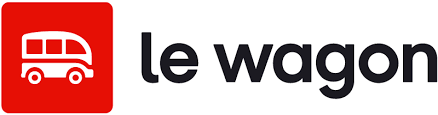

# Eligiendo el Gráfico Correcto

En los notebooks anteriores aprendiste a **crear** gráficos con Plotly Express. Pero saber *cómo* hacer un gráfico no es suficiente — necesitas saber **cuándo** usar cada tipo.

Un gráfico mal elegido puede confundir, engañar o simplemente no comunicar nada útil. Un gráfico bien elegido convierte datos en una historia clara.

**La regla de oro:** La pregunta viene primero, el gráfico después.

**Objetivos de este notebook:**
1. Aprender a identificar qué tipo de pregunta estás haciendo sobre tus datos
2. Conocer el gráfico más adecuado para cada tipo de pregunta
3. Reconocer **anti-patrones**: gráficos mal elegidos y por qué fallan
4. Practicar la selección con ejercicios sobre datasets reales

---

## Configuración

In [2]:
import pandas as pd
import plotly.express as px

In [3]:
# Load all built-in datasets
gapminder = px.data.gapminder()
tips = px.data.tips()
iris = px.data.iris()
stocks = px.data.stocks()
medals = px.data.medals_long()

In [4]:
# Create a filtered version for year 2007
gap_2007 = gapminder[gapminder['year'] == 2007]

---

## Parte 0: El Marco de Decisión

Antes de escribir una sola línea de código, pregúntate: **¿Qué quiero saber de mis datos?**

Toda pregunta sobre datos cae en una de estas 5 categorías:

| Tu pregunta es sobre... | Tipo | Gráfico recomendado | Función Plotly |
|---|---|---|---|
| ¿Cuál es más grande/pequeño? | **Comparación** | Barras | `px.bar()` |
| ¿Cómo se distribuyen los datos? | **Distribución** | Histograma / Boxplot | `px.histogram()` / `px.box()` |
| ¿Están relacionadas 2 variables? | **Relación** | Scatter plot | `px.scatter()` |
| ¿Cómo se divide el total? | **Composición** | Pie / Área apilada | `px.pie()` / `px.area()` |
| ¿Cómo cambia en el tiempo? | **Tendencia** | Línea | `px.line()` |

Esta tabla es tu **referencia rápida**. Vamos a explorar cada categoría con ejemplos, anti-patrones y ejercicios.

---

## Parte 1: Comparación — "¿Cuál es más grande?"

Cuando quieres comparar **valores entre categorías**, el gráfico de barras es tu mejor opción. Es directo, fácil de leer, y permite comparaciones visuales inmediatas.

### 1.1 Barras verticales

**Pregunta:** ¿Cuál continente tiene mayor GDP per cápita promedio en 2007?

Para responder, necesitamos:
1. Filtrar gapminder al año 2007 (ya lo tenemos en `gap_2007`)
2. Agrupar por continente y calcular la media de `gdpPercap`
3. Crear un gráfico de barras

<details><summary markdown='span'>Solución</summary>

```python
avg_gdp = gap_2007.groupby('continent')['gdpPercap'].mean().reset_index()

fig = px.bar(
    avg_gdp,
    x='continent',
    y='gdpPercap',
    title='GDP per cápita promedio por continente (2007)',
    labels={'gdpPercap': 'GDP per cápita (USD)', 'continent': 'Continente'},
    color='continent',
    template='plotly_dark'
)
fig.show()
```
</details>

In [5]:
# TODO: Group gap_2007 by 'continent' and calculate the mean of 'gdpPercap'
# Hint: .groupby('continent')['gdpPercap'].mean().reset_index()
avg_gdp = gap_2007.groupby('continent')['gdpPercap'].mean().reset_index()
print(avg_gdp)

# TODO: Create a bar chart with px.bar()
# Hint: x='continent', y='gdpPercap', color='continent', template='plotly_dark'
fig = px.bar(
    avg_gdp,
    x='continent',
    y='gdpPercap',
    title='GDP per cápita promedio por continente (2007)',
    labels={'gdpPercap': 'GDP per cápita (USD)', 'continent': 'Continente'},
    color='continent',
    template='plotly_dark'
)
fig.show()

  continent     gdpPercap
0    Africa   3089.032605
1  Americas  11003.031625
2      Asia  12473.026870
3    Europe  25054.481636
4   Oceania  29810.188275


> **Observación:** Las barras verticales funcionan bien cuando tienes **pocas categorías** (aquí solo 5 continentes). Los nombres son cortos y se leen fácilmente en el eje X.

### 1.2 Barras horizontales

**Pregunta:** ¿Cuáles son los 15 países con mayor población en 2007?

Cuando tienes **muchas categorías** o nombres largos, las barras horizontales son más legibles.

<details><summary markdown='span'>Solución</summary>

```python
top_15_pop = gap_2007.nlargest(15, 'pop')

fig = px.bar(
    top_15_pop,
    x='pop',
    y='country',
    orientation='h',
    title='Top 15 países por población (2007)',
    labels={'pop': 'Población', 'country': 'País'},
    color='continent',
    template='plotly_dark'
)
fig.update_layout(yaxis={'categoryorder': 'total ascending'})
fig.show()
```
</details>

In [6]:
# TODO: Get the top 15 countries by population from gap_2007
# Hint: use .nlargest(15, 'pop')
top_15_pop = gap_2007.nlargest(15, 'pop')

# TODO: Create a horizontal bar chart with px.bar()
# Hint: x='pop', y='country', orientation='h', template='plotly_dark'
# Bonus: use .update_layout(yaxis={'categoryorder': 'total ascending'}) to sort bars
fig = px.bar(
    top_15_pop,
    x='pop',
    y='country',
    orientation='h',
    title='Top 15 países por población (2007)',
    labels={'pop': 'Población', 'country': 'País'},
    color='continent',
    template='plotly_dark'
)
fig.update_layout(yaxis={'categoryorder': 'total ascending'})
fig.show()

### Anti-patrón: Pie chart con muchas categorías

Un error común es usar un **pie chart** cuando tienes muchas categorías. Ejecuta la celda siguiente para ver por qué es un problema:

In [7]:
# ANTI-PATTERN: Pie chart with 15 categories
top_15_pop = gap_2007.nlargest(15, 'pop')

fig = px.pie(
    top_15_pop,
    values='pop',
    names='country',
    title='ANTI-PATRÓN: Pie chart con 15 países — difícil de comparar',
    template='plotly_dark'
)
fig.show()

> **¿Por qué falla?** Con 15 categorías, las porciones se vuelven muy pequeñas y es casi imposible comparar valores similares. ¿Indonesia es más grande que Brasil? Muy difícil de decir en un pie chart. En un gráfico de barras horizontales, la diferencia es obvia.

### 1.3 Barras agrupadas vs. apiladas

Cuando necesitas comparar valores entre **dos dimensiones** (por ejemplo, país Y tipo de medalla), tienes dos opciones:

- **Agrupadas** (`barmode='group'`): Mejor para comparar valores **individuales** entre categorías
- **Apiladas** (`barmode='stack'`): Mejor para comparar **totales** entre categorías

Vamos a usar el dataset de medallas olímpicas para ver la diferencia.

<details><summary markdown='span'>Solución</summary>

```python
# Grouped: compare individual medal counts
fig_grouped = px.bar(
    medals,
    x='nation',
    y='count',
    color='medal',
    barmode='group',
    title='Medallas por país (agrupadas) — compara valores individuales',
    labels={'count': 'Cantidad', 'nation': 'País', 'medal': 'Medalla'},
    color_discrete_map={'gold': '#FFD700', 'silver': '#C0C0C0', 'bronze': '#CD7F32'},
    template='plotly_dark'
)
fig_grouped.show()

# Stacked: compare total medal counts
fig_stacked = px.bar(
    medals,
    x='nation',
    y='count',
    color='medal',
    barmode='stack',
    title='Medallas por país (apiladas) — compara totales',
    labels={'count': 'Cantidad', 'nation': 'País', 'medal': 'Medalla'},
    color_discrete_map={'gold': '#FFD700', 'silver': '#C0C0C0', 'bronze': '#CD7F32'},
    template='plotly_dark'
)
fig_stacked.show()
```
</details>

In [8]:
# TODO: Create a GROUPED bar chart of medals by nation
# Hint: x='nation', y='count', color='medal', barmode='group'
# Bonus: use color_discrete_map for gold/silver/bronze colors
fig_grouped = px.bar(
    medals,
    x='nation',
    y='count',
    color='medal',
    barmode='group',
    title='Medallas por país (agrupadas) — compara valores individuales',
    labels={'count': 'Cantidad', 'nation': 'País', 'medal': 'Medalla'},
    color_discrete_map={'gold': '#FFD700', 'silver': '#C0C0C0', 'bronze': '#CD7F32'},
    template='plotly_dark'
)
fig_grouped.show()

In [9]:
# TODO: Create a STACKED bar chart of medals by nation
# Hint: same as above but barmode='stack'
fig_stacked = px.bar(
    medals,
    x='nation',
    y='count',
    color='medal',
    barmode='stack',
    title='Medallas por país (apiladas) — compara totales',
    labels={'count': 'Cantidad', 'nation': 'País', 'medal': 'Medalla'},
    color_discrete_map={'gold': '#FFD700', 'silver': '#C0C0C0', 'bronze': '#CD7F32'},
    template='plotly_dark'
)
fig_stacked.show()

#### Ejercicio 1: ¿Agrupado o apilado?

Para cada pregunta, elige **agrupado** o **apilado** y explica por qué:

1. "¿Qué país ganó más medallas de oro?" → ¿agrupado o apilado?
2. "¿Qué país ganó más medallas en total?" → ¿agrupado o apilado?

<details><summary markdown='span'>Respuesta</summary>

1. **Agrupado** — necesitas comparar las barras de oro individualmente entre países. En el apilado, las barras de oro están en la base pero es más difícil comparar su altura exacta.
2. **Apilado** — la altura total de cada barra apilada te da el total de medallas de cada país de un vistazo.
</details>

---

## Parte 2: Distribución — "¿Cómo se reparten los datos?"

Cuando quieres entender la **forma** de tus datos — dónde se concentran, qué tan dispersos están, si hay valores extremos — necesitas gráficos de distribución.

### 2.1 Histograma

**Pregunta:** ¿Cuáles son los montos de cuenta más comunes en el restaurante?

Un histograma divide un rango de valores continuos en **bins** (intervalos) y cuenta cuántos datos caen en cada uno. Te muestra la **forma** de la distribución.

<details><summary markdown='span'>Solución</summary>

```python
fig = px.histogram(
    tips,
    x='total_bill',
    nbins=30,
    title='Distribución de montos de cuenta',
    labels={'total_bill': 'Monto de la cuenta (USD)', 'count': 'Frecuencia'},
    template='plotly_dark'
)
fig.show()
```
</details>

In [10]:
# TODO: Create a histogram of 'total_bill' from the tips dataset
# Hint: px.histogram(tips, x='total_bill', nbins=30, template='plotly_dark')
fig = px.histogram(
    tips,
    x='total_bill',
    nbins=30,
    title='Distribución de montos de cuenta',
    labels={'total_bill': 'Monto de la cuenta (USD)', 'count': 'Frecuencia'},
    template='plotly_dark'
)
fig.show()

### Anti-patrón: Bar chart para datos continuos

Un error frecuente es usar `px.bar()` en vez de `px.histogram()` para datos continuos. Ejecuta esto para ver la diferencia:

In [11]:
# ANTI-PATTERN: Using bar chart for continuous data
fig = px.bar(
    tips.head(50),
    x=tips.head(50).index,
    y='total_bill',
    title='ANTI-PATRÓN: Barras para datos continuos — no muestra la distribución',
    labels={'x': 'Índice', 'total_bill': 'Monto (USD)'},
    template='plotly_dark'
)
fig.show()

> **¿Por qué falla?** Un bar chart muestra cada valor individual como una barra separada. No revela patrones, concentraciones ni forma de la distribución. El histograma agrupa los valores en intervalos y te dice *dónde se concentran* los datos.

### 2.2 Boxplot

**Pregunta:** ¿Varían los montos de cuenta según el día de la semana?

El boxplot es ideal para **comparar distribuciones entre grupos**. En un solo gráfico ves:
- La **mediana** (línea central)
- Los **cuartiles** Q1 y Q3 (bordes de la caja = 50% central de los datos)
- Los **bigotes** (rango sin outliers)
- Los **outliers** (puntos fuera de los bigotes)

<details><summary markdown='span'>Solución</summary>

```python
fig = px.box(
    tips,
    x='day',
    y='total_bill',
    color='day',
    title='Distribución de cuentas por día de la semana',
    labels={'total_bill': 'Monto (USD)', 'day': 'Día'},
    template='plotly_dark'
)
fig.show()
```
</details>

In [12]:
# TODO: Create a boxplot of 'total_bill' grouped by 'day'
# Hint: px.box(tips, x='day', y='total_bill', color='day', template='plotly_dark')
fig = px.box(
    tips,
    x='day',
    y='total_bill',
    color='day',
    title='Distribución de cuentas por día de la semana',
    labels={'total_bill': 'Monto (USD)', 'day': 'Día'},
    template='plotly_dark'
)
fig.show()

### 2.3 Violin

**Pregunta:** ¿Cómo difiere la distribución de propinas entre almuerzo y cena?

El violin plot combina un boxplot con una estimación de densidad. La forma del "violín" te muestra dónde se **concentran** los datos — algo que el boxplot no revela (dos distribuciones pueden tener los mismos cuartiles pero formas muy diferentes).

<details><summary markdown='span'>Solución</summary>

```python
fig = px.violin(
    tips,
    x='time',
    y='tip',
    color='sex',
    box=True,
    title='Distribución de propinas por momento del día y género',
    labels={'tip': 'Propina (USD)', 'time': 'Momento', 'sex': 'Género'},
    template='plotly_dark'
)
fig.show()
```
</details>

In [13]:
# TODO: Create a violin plot of 'tip' by 'time', colored by 'sex'
# Hint: px.violin(tips, x='time', y='tip', color='sex', box=True, template='plotly_dark')
fig = px.violin(
    tips,
    x='time',
    y='tip',
    color='sex',
    box=True,
    title='Distribución de propinas por momento del día y género',
    labels={'tip': 'Propina (USD)', 'time': 'Momento', 'sex': 'Género'},
    template='plotly_dark'
)
fig.show()

#### Ejercicio 2: ¿Histograma o boxplot?

Para cada pregunta sobre el dataset `tips`, elige el gráfico más adecuado, **justifica tu elección** e impleméntalo:

1. "¿Cuál es el rango de propinas más frecuente?" → ¿histograma o boxplot?
2. "¿Los fumadores dan propinas más altas que los no fumadores?" → ¿histograma o boxplot?

<details><summary markdown='span'>Respuesta</summary>

1. **Histograma** — quieres ver la *forma* de la distribución y dónde se concentran los valores. El histograma te muestra directamente qué rango tiene más frecuencia.
2. **Boxplot** — quieres *comparar* las distribuciones de dos grupos (fumadores vs no fumadores). El boxplot te muestra las medianas y cuartiles lado a lado.

```python
# Question 1: Histogram
fig1 = px.histogram(
    tips,
    x='tip',
    nbins=25,
    title='Distribución de propinas — ¿cuál es el rango más frecuente?',
    labels={'tip': 'Propina (USD)'},
    template='plotly_dark'
)
fig1.show()

# Question 2: Boxplot
fig2 = px.box(
    tips,
    x='smoker',
    y='tip',
    color='smoker',
    title='Propinas: fumadores vs no fumadores',
    labels={'tip': 'Propina (USD)', 'smoker': 'Fumador'},
    template='plotly_dark'
)
fig2.show()
```
</details>

In [77]:
# TODO: Question 1 — What is the most common tip range?
# Choose your chart type and implement it
fig1 = px.histogram(
    tips,
    x='tip',
    nbins=25,
    title='Distribución de propinas — ¿cuál es el rango más frecuente?',
    labels={'tip': 'Propina (USD)'},
    template='plotly_dark'
)
fig1.show()

In [78]:
# TODO: Question 2 — Do smokers tip higher than non-smokers?
# Choose your chart type and implement it
fig2 = px.box(
    tips,
    x='smoker',
    y='tip',
    color='smoker',
    title='Propinas: fumadores vs no fumadores',
    labels={'tip': 'Propina (USD)', 'smoker': 'Fumador'},
    template='plotly_dark'
)
fig2.show()

---

## Parte 3: Relación — "¿Están conectadas estas variables?"

Cuando quieres explorar si **dos o más variables numéricas** están relacionadas entre sí, necesitas gráficos de relación.

### 3.1 Scatter plot

**Pregunta:** ¿Existe una relación entre la riqueza de un país y la esperanza de vida?

El scatter plot (gráfico de dispersión) es **el** gráfico para explorar relaciones entre dos variables continuas. Cada punto es una observación posicionada según sus valores en los ejes X e Y.

El dataset `gapminder` tiene una de las visualizaciones de scatter más famosas del mundo (popularizada por Hans Rosling).

<details><summary markdown='span'>Solución</summary>

```python
fig = px.scatter(
    gap_2007,
    x='gdpPercap',
    y='lifeExp',
    color='continent',
    size='pop',
    size_max=60,
    hover_name='country',
    log_x=True,
    title='GDP per cápita vs Esperanza de vida (2007)',
    labels={'gdpPercap': 'GDP per cápita (USD, log)', 'lifeExp': 'Esperanza de vida (años)',
            'continent': 'Continente', 'pop': 'Población'},
    template='plotly_dark'
)
fig.show()
```
</details>

In [79]:
# TODO: Create a scatter plot of gdpPercap vs lifeExp from gap_2007
# Hint: color='continent', size='pop', hover_name='country', log_x=True
# Template: 'plotly_dark'
fig = px.scatter(
    gap_2007,
    x='gdpPercap',
    y='lifeExp',
    color='continent',
    size='pop',
    size_max=60,
    hover_name='country',
    log_x=True,
    title='GDP per cápita vs Esperanza de vida (2007)',
    labels={'gdpPercap': 'GDP per cápita (USD, log)', 'lifeExp': 'Esperanza de vida (años)',
            'continent': 'Continente', 'pop': 'Población'},
    template='plotly_dark'
)
fig.show()

> **Observación:** Cada punto es un país. El tamaño indica su población, el color su continente. Con un solo gráfico estamos mostrando **4 dimensiones** de datos (GDP, esperanza de vida, población, continente). El `log_x=True` ayuda a separar los países de menor GDP.

### Anti-patrón: Líneas entre puntos no conectados

Un error común es usar `px.line()` cuando los datos no tienen un orden secuencial natural. Ejecuta esto para ver el problema:

In [17]:
# ANTI-PATTERN: Using line chart for unordered data
fig = px.line(
    gap_2007.sort_values('gdpPercap'),
    x='gdpPercap',
    y='lifeExp',
    title='ANTI-PATRÓN: Línea para datos sin orden secuencial — confuso',
    labels={'gdpPercap': 'GDP per cápita', 'lifeExp': 'Esperanza de vida'},
    template='plotly_dark'
)
fig.show()

> **¿Por qué falla?** Las líneas implican **conexión secuencial** entre puntos. Si los puntos no tienen un orden natural (como el tiempo), las líneas crean una forma caótica sin significado. El scatter muestra cada punto independiente, que es lo que necesitamos.

### 3.2 Scatter matrix

**Pregunta:** ¿Cómo se relacionan entre sí las 4 medidas de una flor iris?

Cuando tienes **múltiples variables numéricas** y quieres una vista rápida de todas las relaciones posibles, el scatter matrix genera un scatter plot por cada par de variables.

<details><summary markdown='span'>Solución</summary>

```python
fig = px.scatter_matrix(
    iris,
    dimensions=['sepal_length', 'sepal_width', 'petal_length', 'petal_width'],
    color='species',
    title='Scatter Matrix — Iris dataset',
    template='plotly_dark'
)
fig.update_traces(diagonal_visible=False)
fig.show()
```
</details>

In [18]:
# TODO: Create a scatter matrix of the 4 numeric columns from the iris dataset
# Hint: dimensions=['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
# Hint: color='species', template='plotly_dark'
fig = px.scatter_matrix(
    iris,
    dimensions=['sepal_length', 'sepal_width', 'petal_length', 'petal_width'],
    color='species',
    title='Scatter Matrix — Iris dataset',
    template='plotly_dark'
)
fig.update_traces(diagonal_visible=False)
fig.show()

> **Observación:** El scatter matrix es una herramienta de **exploración rápida**, no de presentación. Te permite identificar de un vistazo cuáles pares de variables tienen relaciones interesantes para luego analizarlas con un scatter individual.

### 3.3 Heatmap de correlación

**Pregunta:** ¿Qué tan fuerte es la correlación entre las variables del iris?

El heatmap de correlación complementa al scatter matrix: en lugar de mostrar cada punto, muestra un **número** que resume la fuerza de la relación (-1 a 1).

<details><summary markdown='span'>Solución</summary>

```python
numeric_cols = iris[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']]
correlation = numeric_cols.corr()

fig = px.imshow(
    correlation,
    text_auto='.2f',
    color_continuous_scale='RdBu_r',
    aspect='equal',
    title='Matriz de correlación — Iris',
    zmin=-1,
    zmax=1,
    template='plotly_dark'
)
fig.show()
```
</details>

In [39]:
# TODO: Calculate the correlation matrix of the iris numeric columns
# Hint: iris[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']].corr()

# TODO: Create a heatmap with px.imshow()
# Hint: text_auto='.2f', color_continuous_scale='RdBu_r', zmin=-1, zmax=1

numeric_cols = iris[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']]
correlation = numeric_cols.corr()

fig = px.imshow(
    correlation,
    text_auto='.2f',
    color_continuous_scale='RdBu_r',
    aspect='equal',
    title='Matriz de correlación — Iris',
    zmin=-1,
    zmax=1,
    template='plotly_dark'
)
fig.show()

#### Ejercicio 3: ¿Scatter o heatmap?

Para cada pregunta sobre el dataset `iris`, elige el gráfico más adecuado e impleméntalo:

1. "¿Es cierto que las flores con pétalos más largos también tienen pétalos más anchos?" → ¿scatter o heatmap?
2. "¿Cuál par de variables tiene la correlación más fuerte?" → ¿scatter o heatmap?

<details><summary markdown='span'>Respuesta</summary>

1. **Scatter** — quieres ver la relación *detallada* entre dos variables específicas, incluyendo la forma de la nube de puntos y si hay agrupaciones por especie.
2. **Heatmap** — quieres comparar *todas* las correlaciones de un vistazo para encontrar la más fuerte, sin necesidad de ver los puntos individuales.

```python
# Question 1: Scatter
fig1 = px.scatter(
    iris,
    x='petal_length',
    y='petal_width',
    color='species',
    title='Longitud vs Ancho de pétalo — ¿están relacionados?',
    labels={'petal_length': 'Longitud del pétalo', 'petal_width': 'Ancho del pétalo'},
    template='plotly_dark'
)
fig1.show()

# Question 2: Heatmap
correlation = iris[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']].corr()
fig2 = px.imshow(
    correlation,
    text_auto='.2f',
    color_continuous_scale='RdBu_r',
    aspect='equal',
    title='¿Cuál correlación es más fuerte?',
    zmin=-1,
    zmax=1,
    template='plotly_dark'
)
fig2.show()
```
</details>

In [40]:
# TODO: Question 1 — Are longer petals also wider?
# Choose your chart type and implement it
fig1 = px.scatter(
    iris,
    x='petal_length',
    y='petal_width',
    color='species',
    title='Longitud vs Ancho de pétalo — ¿están relacionados?',
    labels={'petal_length': 'Longitud del pétalo', 'petal_width': 'Ancho del pétalo'},
    template='plotly_dark'
)
fig1.show()

In [42]:
# TODO: Question 2 — Which pair of variables has the strongest correlation?
# Choose your chart type and implement it
correlation = iris[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']].corr()
fig2 = px.imshow(
    correlation,
    text_auto='.2f',
    color_continuous_scale='RdBu_r',
    aspect='equal',
    title='¿Cuál correlación es más fuerte?',
    zmin=-1,
    zmax=1,
    template='plotly_dark'
)
fig2.show()

---

## Parte 4: Composición — "¿Cómo se divide el total?"

Cuando quieres mostrar las **partes de un todo** — cómo se compone un total — usas gráficos de composición.

### 4.1 Pie chart

**Pregunta:** ¿Qué proporción de la población mundial tiene cada continente en 2007?

El pie chart funciona **solo** cuando:
- Tienes **pocas categorías** (idealmente 2-5)
- Los valores representan **partes de un todo** (suman ~100%)

<details><summary markdown='span'>Solución</summary>

```python
pop_by_continent = gap_2007.groupby('continent')['pop'].sum().reset_index()

fig = px.pie(
    pop_by_continent,
    values='pop',
    names='continent',
    title='Población mundial por continente (2007)',
    template='plotly_dark'
)
fig.show()
```
</details>

In [43]:
# TODO: Group gap_2007 by continent and sum the population
# Hint: .groupby('continent')['pop'].sum().reset_index()

# TODO: Create a pie chart with px.pie()
# Hint: values='pop', names='continent', template='plotly_dark'
pop_by_continent = gap_2007.groupby('continent')['pop'].sum().reset_index()

fig = px.pie(
    pop_by_continent,
    values='pop',
    names='continent',
    title='Población mundial por continente (2007)',
    template='plotly_dark'
)
fig.show()

### Anti-patrón: Pie chart con valores que no suman un total

El pie chart **no funciona** cuando los valores no representan partes de un todo. Ejecuta esto para ver el problema:

In [23]:
# ANTI-PATTERN: Pie chart with values that don't represent parts of a whole
avg_gdp = gap_2007.groupby('continent')['gdpPercap'].mean().reset_index()

fig = px.pie(
    avg_gdp,
    values='gdpPercap',
    names='continent',
    title='ANTI-PATRÓN: GDP promedio como "partes" — no son partes de un total',
    template='plotly_dark'
)
fig.show()

> **¿Por qué falla?** El GDP per cápita promedio de cada continente **no** es una "porción" de un total. No tendría sentido sumarlos. Cada segmento del pie implica que su continente "tiene" esa proporción del GDP mundial, lo cual es falso. Para comparar promedios, un gráfico de barras es mucho más claro y honesto.

### 4.2 Área apilada

**Pregunta:** ¿Cómo ha cambiado la composición de la población mundial por continente a lo largo del tiempo?

El área apilada es como un **pie chart que evoluciona en el tiempo**. Muestra cómo las proporciones cambian a lo largo de un eje temporal.

<details><summary markdown='span'>Solución</summary>

```python
pop_over_time = gapminder.groupby(['year', 'continent'])['pop'].sum().reset_index()

fig = px.area(
    pop_over_time,
    x='year',
    y='pop',
    color='continent',
    title='Evolución de la población mundial por continente',
    labels={'pop': 'Población', 'year': 'Año', 'continent': 'Continente'},
    template='plotly_dark'
)
fig.show()
```
</details>

In [44]:
# TODO: Group gapminder by year and continent, sum the population
# Hint: .groupby(['year', 'continent'])['pop'].sum().reset_index()

# TODO: Create a stacked area chart with px.area()
# Hint: x='year', y='pop', color='continent', template='plotly_dark'
pop_over_time = gapminder.groupby(['year', 'continent'])['pop'].sum().reset_index()

fig = px.area(
    pop_over_time,
    x='year',
    y='pop',
    color='continent',
    title='Evolución de la población mundial por continente',
    labels={'pop': 'Población', 'year': 'Año', 'continent': 'Continente'},
    template='plotly_dark'
)
fig.show()

#### Ejercicio 4: ¿Pie o barra?

Para cada pregunta, elige **pie** o **barra** e impleméntalo:

1. "¿Qué proporción de las mesas en el restaurante son de fumadores vs no fumadores?" (dataset `tips`)
2. "¿Cuál continente tiene mayor esperanza de vida promedio?" (dataset `gap_2007`)

<details><summary markdown='span'>Respuesta</summary>

1. **Pie** — son solo 2 categorías (Yes/No) y representan partes de un todo (todas las mesas del restaurante). Caso ideal para pie chart.
2. **Barra** — quieres comparar promedios entre continentes. Los promedios no son "partes de un total", así que el pie sería engañoso.

```python
# Question 1: Pie (proportions of a whole)
smoker_counts = tips['smoker'].value_counts().reset_index()
fig1 = px.pie(
    smoker_counts,
    values='count',
    names='smoker',
    title='Proporción de mesas: fumadores vs no fumadores',
    template='plotly_dark'
)
fig1.show()

# Question 2: Bar (comparing averages, not parts of a whole)
avg_life = gap_2007.groupby('continent')['lifeExp'].mean().reset_index()
fig2 = px.bar(
    avg_life,
    x='continent',
    y='lifeExp',
    color='continent',
    title='Esperanza de vida promedio por continente (2007)',
    labels={'lifeExp': 'Esperanza de vida (años)', 'continent': 'Continente'},
    template='plotly_dark'
)
fig2.show()
```
</details>

In [45]:
# TODO: Question 1 — What proportion of tables are smokers vs non-smokers?
# Choose your chart type and implement it
smoker_counts = tips['smoker'].value_counts().reset_index()
fig1 = px.pie(
    smoker_counts,
    values='count',
    names='smoker',
    title='Proporción de mesas: fumadores vs no fumadores',
    template='plotly_dark'
)
fig1.show()

In [46]:
# TODO: Question 2 — Which continent has the highest average life expectancy?
# Choose your chart type and implement it

avg_life = gap_2007.groupby('continent')['lifeExp'].mean().reset_index()
fig2 = px.bar(
    avg_life,
    x='continent',
    y='lifeExp',
    color='continent',
    title='Esperanza de vida promedio por continente (2007)',
    labels={'lifeExp': 'Esperanza de vida (años)', 'continent': 'Continente'},
    template='plotly_dark'
)
fig2.show()

---

## Parte 5: Tendencia — "¿Cómo cambia en el tiempo?"

Cuando quieres ver la **evolución temporal** de una variable, el gráfico de líneas es casi siempre la respuesta correcta.

### 5.1 Línea simple

**Pregunta:** ¿Cómo evolucionó el precio de la acción de Google?

El gráfico de líneas funciona porque los datos tienen un **orden temporal natural**: cada punto está conectado al siguiente en el tiempo, y la línea muestra la tendencia.

<details><summary markdown='span'>Solución</summary>

```python
fig = px.line(
    stocks,
    x='date',
    y='GOOG',
    title='Precio de Google (normalizado)',
    labels={'GOOG': 'Precio normalizado', 'date': 'Fecha'},
    template='plotly_dark'
)
fig.show()
```
</details>

In [47]:
# TODO: Create a line chart of GOOG price from the stocks dataset
# Hint: px.line(stocks, x='date', y='GOOG', template='plotly_dark')
fig = px.line(
    stocks,
    x='date',
    y='GOOG',
    title='Precio de Google (normalizado)',
    labels={'GOOG': 'Precio normalizado', 'date': 'Fecha'},
    template='plotly_dark'
)
fig.show()

### Anti-patrón: Barras para series temporales

Ejecuta esto para ver por qué las barras no funcionan bien para series temporales densas:

In [28]:
# ANTI-PATTERN: Bar chart for time series
fig = px.bar(
    stocks,
    x='date',
    y='GOOG',
    title='ANTI-PATRÓN: Barras para serie temporal — se pierde la tendencia',
    labels={'GOOG': 'Precio', 'date': 'Fecha'},
    template='plotly_dark'
)
fig.show()

> **¿Por qué falla?** Con muchos puntos temporales, las barras se vuelven tan delgadas que parecen una masa sólida. La tendencia se pierde porque el ojo no puede seguir los "picos" de las barras tan fácilmente como una línea continua. Las barras son mejores para datos temporales **espaciados** (ej: ventas por mes), mientras que las líneas son mejores para datos **densos** (ej: precios diarios).

### 5.2 Múltiples líneas

**Pregunta:** ¿Cómo se compara el rendimiento de varias acciones tecnológicas?

Para comparar tendencias de múltiples series, transforma tu DataFrame de formato ancho a largo con `.melt()` y usa el parámetro `color`.

<details><summary markdown='span'>Solución</summary>

```python
stocks_long = stocks.melt(id_vars='date', var_name='Ticker', value_name='Price')

fig = px.line(
    stocks_long,
    x='date',
    y='Price',
    color='Ticker',
    title='Comparación de acciones tecnológicas (precios normalizados)',
    labels={'Price': 'Precio normalizado', 'date': 'Fecha'},
    template='plotly_dark'
)
fig.show()
```
</details>

In [49]:
# TODO: Transform stocks from wide to long format using .melt()
# Hint: stocks.melt(id_vars='date', var_name='Ticker', value_name='Price')

# TODO: Create a multi-line chart with px.line() using color='Ticker'
# Template: 'plotly_dark'
stocks_long = stocks.melt(id_vars='date', var_name='Ticker', value_name='Price')

print (stocks_long)
fig = px.line(
    stocks_long,
    x='date',
    y='Price',
    color='Ticker',
    title='Comparación de acciones tecnológicas (precios normalizados)',
    labels={'Price': 'Precio normalizado', 'date': 'Fecha'},
    template='plotly_dark'
)
fig.show()

           date Ticker     Price
0    2018-01-01   GOOG  1.000000
1    2018-01-08   GOOG  1.018172
2    2018-01-15   GOOG  1.032008
3    2018-01-22   GOOG  1.066783
4    2018-01-29   GOOG  1.008773
..          ...    ...       ...
625  2019-12-02   MSFT  1.720717
626  2019-12-09   MSFT  1.752239
627  2019-12-16   MSFT  1.784896
628  2019-12-23   MSFT  1.802472
629  2019-12-30   MSFT  1.788185

[630 rows x 3 columns]


#### Ejercicio 5: Tendencia correcta

**Pregunta:** ¿Cómo ha evolucionado la esperanza de vida promedio por continente desde 1952 hasta 2007?

Usando el dataset `gapminder` (completo, no solo 2007), agrupa por año y continente, calcula la media de `lifeExp`, y elige el gráfico de tendencia más adecuado.

<details><summary markdown='span'>Solución</summary>

```python
life_over_time = gapminder.groupby(['year', 'continent'])['lifeExp'].mean().reset_index()

fig = px.line(
    life_over_time,
    x='year',
    y='lifeExp',
    color='continent',
    title='Evolución de la esperanza de vida por continente',
    labels={'lifeExp': 'Esperanza de vida (años)', 'year': 'Año', 'continent': 'Continente'},
    markers=True,
    template='plotly_dark'
)
fig.show()
```
</details>

In [50]:
# TODO: Group gapminder by year and continent, calculate the mean of lifeExp

# TODO: Create a multi-line chart showing the trend
# Hint: use markers=True to mark the data points
life_over_time = gapminder.groupby(['year', 'continent'])['lifeExp'].mean().reset_index()

fig = px.line(
    life_over_time,
    x='year',
    y='lifeExp',
    color='continent',
    title='Evolución de la esperanza de vida por continente',
    labels={'lifeExp': 'Esperanza de vida (años)', 'year': 'Año', 'continent': 'Continente'},
    markers=True,
    template='plotly_dark'
)
fig.show()

---

## Parte 6: Desafío Final — Elige tu Gráfico

Ahora es tu turno. Para cada pregunta debes:
1. **Identificar** qué tipo de pregunta es (comparación, distribución, relación, composición o tendencia)
2. **Elegir** el gráfico más adecuado
3. **Implementarlo** con Plotly Express

No hay hints esta vez — usa tu marco de decisión.

### Challenge A: Gapminder

Usa los datasets `gapminder` y/o `gap_2007` para responder estas preguntas. Cada pregunta requiere un **gráfico diferente**.

**A1.** ¿Cuáles son los 10 países con mayor GDP per cápita en 2007?

<details><summary markdown='span'>Pista</summary>

Tipo: **Comparación** → barras horizontales (muchos nombres de países)
</details>

In [57]:
# TODO: A1 — Top 10 countries by GDP per capita in 2007

top_10_gdp = gap_2007.nlargest(10, 'gdpPercap')
print(top_10_gdp)

fig = px.bar(
    top_10_gdp,
    x='gdpPercap',
    y='country',
    orientation='h',
    title='Top 10 paises por GDP (2007)',
    labels={'pop': 'GDP', 'country': 'País'},
    color='continent',
    template='plotly_dark'
)
fig.update_layout(yaxis={'categoryorder': 'total ascending'})
fig.show()

               country continent  year  lifeExp        pop    gdpPercap  \
1151            Norway    Europe  2007   80.196    4627926  49357.19017   
863             Kuwait      Asia  2007   77.588    2505559  47306.98978   
1367         Singapore      Asia  2007   79.972    4553009  47143.17964   
1619     United States  Americas  2007   78.242  301139947  42951.65309   
755            Ireland    Europe  2007   78.885    4109086  40675.99635   
671   Hong Kong, China      Asia  2007   82.208    6980412  39724.97867   
1487       Switzerland    Europe  2007   81.701    7554661  37506.41907   
1091       Netherlands    Europe  2007   79.762   16570613  36797.93332   
251             Canada  Americas  2007   80.653   33390141  36319.23501   
695            Iceland    Europe  2007   81.757     301931  36180.78919   

     iso_alpha  iso_num  
1151       NOR      578  
863        KWT      414  
1367       SGP      702  
1619       USA      840  
755        IRL      372  
671        HKG    

**A2.** ¿Cómo se distribuye la esperanza de vida en el mundo en 2007?

<details><summary markdown='span'>Pista</summary>

Tipo: **Distribución** → histograma
</details>

In [61]:
# TODO: A2 — Distribution of life expectancy in 2007
print(gap_2007)

fig = px.histogram(
    gap_2007,
    x='lifeExp',
    nbins=5,
    title='Distribución de esperanza de vida (2007)',
    labels={'lifeExp': 'Esperanza de vida (años)', 'count': 'Cantidad de países'},
    template='plotly_dark'
)
fig.show()

                 country continent  year  lifeExp       pop     gdpPercap  \
11           Afghanistan      Asia  2007   43.828  31889923    974.580338   
23               Albania    Europe  2007   76.423   3600523   5937.029526   
35               Algeria    Africa  2007   72.301  33333216   6223.367465   
47                Angola    Africa  2007   42.731  12420476   4797.231267   
59             Argentina  Americas  2007   75.320  40301927  12779.379640   
...                  ...       ...   ...      ...       ...           ...   
1655             Vietnam      Asia  2007   74.249  85262356   2441.576404   
1667  West Bank and Gaza      Asia  2007   73.422   4018332   3025.349798   
1679         Yemen, Rep.      Asia  2007   62.698  22211743   2280.769906   
1691              Zambia    Africa  2007   42.384  11746035   1271.211593   
1703            Zimbabwe    Africa  2007   43.487  12311143    469.709298   

     iso_alpha  iso_num  
11         AFG        4  
23         ALB        8

**A3.** ¿Existe una relación entre GDP per cápita y esperanza de vida?

<details><summary markdown='span'>Pista</summary>

Tipo: **Relación** → scatter plot
</details>

In [66]:
# TODO: A3 — Relationship between GDP and life expectancy
fig = px.scatter_matrix(
    gap_2007,
    dimensions=['gdpPercap', 'lifeExp'],
    color='continent',
    title='Relación entre GDP per cápita y esperanza de vida (2007)',
    labels={'gdpPercap': 'GDP per cápita (USD)', 'lifeExp': 'Esperanza de vida'},
    template='plotly_dark'
)
fig.show()

**A4.** ¿Cómo ha evolucionado la composición de la población mundial por continente desde 1952?

<details><summary markdown='span'>Pista</summary>

Tipo: **Composición en el tiempo** → área apilada
</details>

In [67]:
# TODO: A4 — World population composition over time
pop_time = gapminder.groupby(['year', 'continent'])['pop'].sum().reset_index()

fig = px.area(
    pop_time,
    x='year',
    y='pop',
    color='continent',
    title='Evolución de la población mundial por continente',
    labels={'pop': 'Población', 'year': 'Año', 'continent': 'Continente'},
    template='plotly_dark'
)
fig.show()

### Challenge B: Tips

Usa el dataset `tips` para responder estas preguntas. Cada pregunta requiere un **gráfico diferente**.

**B1.** ¿Qué día de la semana genera más ingresos para el restaurante?

<details><summary markdown='span'>Pista</summary>

Tipo: **Comparación** → barras
</details>

In [71]:
# TODO: B1 — Revenue by day of the week
rev_by_day = tips.groupby('day')['total_bill'].sum().reset_index()
print(tips['day'].drop_duplicates())
fig_b1 = px.bar(
    rev_by_day,
    x='day',
    y='total_bill',
    color='day',
    title='Ingresos totales por día de la semana',
    labels={'total_bill': 'Ingresos (USD)', 'day': 'Día'},
    template='plotly_dark'
)
fig_b1.show()

0      Sun
19     Sat
77    Thur
90     Fri
Name: day, dtype: object


**B2.** ¿Varían las propinas entre el almuerzo y la cena?

<details><summary markdown='span'>Pista</summary>

Tipo: **Distribución** → boxplot o violin
</details>

In [74]:
# TODO: B2 — Tip distribution: lunch vs dinner
fig_b2 = px.violin(
    tips,
    x='time',
    y='tip',
    color='time',
    title='Distribución de propinas: Almuerzo vs Cena',
    labels={'tip': 'Propina (USD)', 'time': 'Momento'},
    template='plotly_dark'
)
fig_b2.show()

**B3.** ¿Existe una relación entre el monto total de la cuenta y la propina?

<details><summary markdown='span'>Pista</summary>

Tipo: **Relación** → scatter plot
</details>

In [75]:
# TODO: B3 — Relationship between total bill and tip
fig_b3 = px.scatter(
    tips,
    x='total_bill',
    y='tip',
    color='time',
    title='Relación entre cuenta y propina',
    labels={'total_bill': 'Cuenta (USD)', 'tip': 'Propina (USD)'},
    template='plotly_dark'
)
fig_b3.show()

**B4.** ¿Qué proporción de clientes son fumadores vs no fumadores?

<details><summary markdown='span'>Pista</summary>

Tipo: **Composición** → pie chart (solo 2 categorías, partes de un todo)
</details>

In [76]:
# TODO: B4 — Proportion of smokers vs non-smokers
smoker_counts = tips['smoker'].value_counts().reset_index()
fig_b4 = px.pie(
    smoker_counts,
    values='count',
    names='smoker',
    title='Proporción de clientes: fumadores vs no fumadores',
    template='plotly_dark'
)
fig_b4.show()

<details><summary markdown='span'>Soluciones del Desafío Final</summary>

```python
# A1: Horizontal bar — Top 10 GDP per capita
top_10_gdp = gap_2007.nlargest(10, 'gdpPercap')
fig_a1 = px.bar(
    top_10_gdp, x='gdpPercap', y='country', orientation='h',
    title='Top 10 países por GDP per cápita (2007)',
    labels={'gdpPercap': 'GDP per cápita (USD)', 'country': 'País'},
    color='continent', template='plotly_dark'
)
fig_a1.update_layout(yaxis={'categoryorder': 'total ascending'})
fig_a1.show()

# A2: Histogram — Life expectancy distribution
fig_a2 = px.histogram(
    gap_2007, x='lifeExp', nbins=25,
    title='Distribución de esperanza de vida en el mundo (2007)',
    labels={'lifeExp': 'Esperanza de vida (años)'},
    template='plotly_dark'
)
fig_a2.show()

# A3: Scatter — GDP vs life expectancy
fig_a3 = px.scatter(
    gap_2007, x='gdpPercap', y='lifeExp', color='continent',
    size='pop', size_max=60, hover_name='country', log_x=True,
    title='GDP per cápita vs Esperanza de vida (2007)',
    labels={'gdpPercap': 'GDP per cápita (USD, log)', 'lifeExp': 'Esperanza de vida'},
    template='plotly_dark'
)
fig_a3.show()

# A4: Stacked area — Population composition
pop_time = gapminder.groupby(['year', 'continent'])['pop'].sum().reset_index()
fig_a4 = px.area(
    pop_time, x='year', y='pop', color='continent',
    title='Evolución de la población mundial por continente',
    labels={'pop': 'Población', 'year': 'Año', 'continent': 'Continente'},
    template='plotly_dark'
)
fig_a4.show()

# B1: Bar — Revenue by day
rev_by_day = tips.groupby('day')['total_bill'].sum().reset_index()
fig_b1 = px.bar(
    rev_by_day, x='day', y='total_bill', color='day',
    title='Ingresos totales por día de la semana',
    labels={'total_bill': 'Ingresos (USD)', 'day': 'Día'},
    template='plotly_dark'
)
fig_b1.show()

# B2: Box — Tips lunch vs dinner
fig_b2 = px.box(
    tips, x='time', y='tip', color='time',
    title='Distribución de propinas: Almuerzo vs Cena',
    labels={'tip': 'Propina (USD)', 'time': 'Momento'},
    template='plotly_dark'
)
fig_b2.show()

# B3: Scatter — Bill vs tip
fig_b3 = px.scatter(
    tips, x='total_bill', y='tip', color='time',
    title='Relación entre cuenta y propina',
    labels={'total_bill': 'Cuenta (USD)', 'tip': 'Propina (USD)'},
    template='plotly_dark'
)
fig_b3.show()

# B4: Pie — Smokers vs non-smokers
smoker_counts = tips['smoker'].value_counts().reset_index()
fig_b4 = px.pie(
    smoker_counts, values='count', names='smoker',
    title='Proporción de clientes: fumadores vs no fumadores',
    template='plotly_dark'
)
fig_b4.show()
```
</details>

---

## Resumen y Referencia Rápida

### Tabla de decisión

| Pregunta | Tipo | Gráfico | Función | Cuándo usarlo |
|---|---|---|---|---|
| ¿Cuál es más grande? | Comparación | Barras verticales | `px.bar()` | Pocas categorías, nombres cortos |
| ¿Cuál es más grande? | Comparación | Barras horizontales | `px.bar(orientation='h')` | Muchas categorías o nombres largos |
| ¿Cuál tiene más en total? | Comparación | Barras apiladas | `px.bar(barmode='stack')` | Comparar totales entre grupos |
| ¿Cómo se distribuyen? | Distribución | Histograma | `px.histogram()` | Forma de distribución, valores frecuentes |
| ¿Difieren los grupos? | Distribución | Boxplot | `px.box()` | Comparar distribuciones entre grupos |
| ¿Cómo se concentran? | Distribución | Violin | `px.violin()` | Distribución detallada con densidad |
| ¿Están relacionadas? | Relación | Scatter | `px.scatter()` | Relación entre 2 variables continuas |
| ¿Qué correlaciones hay? | Relación | Heatmap | `px.imshow()` + `.corr()` | Vista rápida de muchas correlaciones |
| ¿Cómo se divide el total? | Composición | Pie | `px.pie()` | 2-5 categorías, partes de un todo |
| ¿Cómo cambia la composición? | Composición | Área apilada | `px.area()` | Composición que evoluciona en el tiempo |
| ¿Cómo cambia en el tiempo? | Tendencia | Línea | `px.line()` | Datos con orden temporal |

### Anti-patrones comunes

| Evita esto... | Usa esto en su lugar | Por qué |
|---|---|---|
| Pie chart con >5 categorías | Barras horizontales | Las porciones pequeñas son imposibles de comparar |
| Bar chart para datos continuos | Histograma | Las barras no muestran la forma de la distribución |
| Líneas entre puntos sin orden | Scatter plot | Las líneas implican conexión secuencial |
| Pie con valores que no suman un total | Barras | El pie implica "partes de un todo" |
| Barras para series temporales densas | Línea | Las barras ocultan la tendencia con muchos puntos |